# Transects in ACCESS-OM3 and ACCESS-OM2

Transects of 1993-2017 mean potential temperature and salinity near WOCE/GO-SHIP hydrographic lines, compared to climatologies (1985-2013) from WOA23.

Based on in Figs 14, 20, 23, 25 of [Kiss et al 2020](https://doi.org/10.5194/gmd-13-401-2020) - see code [here](https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/blob/master/figures/WOCE_transects/Plot_WOCE_transects.ipynb).

- SR3 (Fig 14)
- P16 (Fig 20)
- A16 (Fig 23)
- IO8, IO9 (Fig 25)

Related issue:
- https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/13

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-03-06-2026/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/datastores/MC_25km_jra_ryf+wombatlite-test3-f4d79e82/experiment_datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-0934636/notebooks/mkfigs_output_MC_25km_jra_ryf+wombatlite-test3-f4d79e82/"
nbname = "Transects.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from exptdata_access import guess_experiment_from_esm_file
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

In [4]:
import intake
from dask.distributed import Client
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import cmocean
import cartopy.crs as ccrs
import cftime
import cf_xarray as cfxr
import cf_xarray.units
import numpy as np
import xarray as xr

In [5]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [6]:
from model_agnostic import patch_broken_conda_env, patch_dask_workers
patch_broken_conda_env()   # no-op on healthy conda envs
client = Client(threads_per_worker=1)
patch_dask_workers(client)  # patch workers too
print(client.dashboard_link)
client

http://127.0.0.1:8787/status


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:38903,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:39303,Total threads: 1
Dashboard: http://127.0.0.1:41985/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:35053,


In [7]:
IAF = esm_file.find('iaf') > 0
IAF
# Averaging window for RYF runs: last NYEARS complete years, or an explicit [first, last] period.
# (IAF runs keep the last-25-years overlap with the OM2 IAF run, unless averaging_period is given.)
averaging_period = None   # e.g. [1908, 1909]; None = automatic
NYEARS = 2
from model_agnostic import years_window, year_slice

## Load ACCESS-OM3 data from ESM datastore

In [8]:
if model_name == "ACCESS-CM3":
    catalogs = [esm_file]
else:
    catalogs = [
                # '/g/data/ol01/access-om3-output/access-om3-025/MC_25km_jra_ryf-1.0-beta/experiment_datastore.json',
                # '/g/data/ol01/access-om3-output/access-om3-025/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json',
                esm_file,
                # '/scratch/tm70/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test4-rerun-099ed2b5/datastore.json',
                # '/scratch/tm70/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5test-67872f64/datastore.json',
                # '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5-38867fcd/datastore.json',
                # '/scratch/x77/aek156/access-om3/archive/MC_25km_era_iaf+wombatlite-test5-era-8a51ed1d/datastore.json',
                # '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test-test5-tweaks-dd8d35ed/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',
            ]
catalogs

['/g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/datastores/MC_25km_jra_ryf+wombatlite-test3-f4d79e82/experiment_datastore.json']

In [9]:
om3datastores = { os.path.normpath(c).split(os.sep)[-2]:
               intake.open_esm_datastore(c,
                                         columns_with_iterables=[
                                            "variable",
                                            "variable_long_name",
                                            "variable_standard_name",
                                            "variable_cell_methods",
                                            "variable_units"]
                                        )
              for c in catalogs }
om3datastores

{'MC_25km_jra_ryf+wombatlite-test3-f4d79e82': <experiment_datastore catalog with 23 dataset(s) from 1534 asset(s)>}

In [10]:
om3exptname = os.path.basename(os.path.dirname(esm_file))
om3exptname

'MC_25km_jra_ryf+wombatlite-test3-f4d79e82'

## Load data from ACCESS-OM3

In [11]:
om3varnames = [ 'thetao', 'so' ]  # potential temperature and practical salinity

om3chunks = {"time": -1, "z_l": "auto", "yh": "auto", "xh": "auto"}  # chunk space too, or 8km chunks are >10GB
if model_name == "ACCESS-CM3":
    om3chunks = {"time": 1}  # CM3 stores yearly files

om3data = {
            expt: ds.search(variable=om3varnames).to_dask(
                xarray_open_kwargs = dict(
                    chunks=om3chunks,
                    decode_timedelta=True
                )
            )
            for expt, ds in om3datastores.items()
          }

if IAF or model_name == "ACCESS-CM3":  # common calendar for obs overlays
    for expt, ds in om3data.items():
        try:
            om3data[expt] = ds.convert_calendar("proleptic_gregorian", use_cftime=True)
        except KeyError:
            pass

om3mask = np.isfinite(om3data[om3exptname][om3varnames[0]].isel(time=0)).load()

## Load data from ACCESS-OM2
use control - see https://forum.access-hive.org.au/t/access-om2-control-experiments/258#p-747-ryf-7

In [12]:
if IAF:
    om2exptname = '025deg_jra55_iaf_omip2_cycle1'
else:
    om2exptname = '025deg_jra55_ryf9091_gadi'  # monthly temp only for 1900-1903, and 2300-, with annual data in the gap
om2frequency = "1mon" if IAF else "1yr"  # 025deg_jra55_ryf9091_gadi only has pot_temp as annual means
om2datastores = {om2exptname: intake.cat.access_nri[om2exptname]}

In [13]:
om2varnames = [ 'pot_temp', 'salt' ]  # potential temperature and practical salinity

om2data = {
            expt: ds.search(variable=om2varnames, frequency=om2frequency).to_dask(
                xarray_open_kwargs = dict(
                    chunks={"xt_ocean": "auto", "yt_ocean": "auto", "st_ocean" : "auto"},
                    decode_timedelta=True
                )
            )
            for expt, ds in om2datastores.items()
          }

if IAF or model_name == "ACCESS-CM3":  # common calendar for obs overlays
    for expt, ds in om2data.items():
        try:
            om2data[expt] = ds.convert_calendar("proleptic_gregorian", use_cftime=True)
        except KeyError:
            pass

for expt, ds in om2data.items():
    try:
        om2data[expt]['pot_temp'] = ds['pot_temp'] - 273.15  # convert to degC
        om2data[expt]['pot_temp'].attrs['units'] = 'degC'
    except KeyError:
        pass

om2mask = np.isfinite(om2data[om2exptname][om2varnames[0]].isel(time=0)).load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='pot_temp' → variable=['pot_temp','pot_temp']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='salt' → variable=['salt','salt']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

## Set time range and calculate time average

In [14]:
firsttime = []
lasttime = []
for expt, ds in om3data.items():
    firsttime.append(ds.time.values[0])
    lasttime.append(ds.time.values[-1])
for expt, ds in om2data.items():
    firsttime.append(ds.time.values[0])
    lasttime.append(ds.time.values[-1])

if averaging_period is not None:
    # explicit period for both models (must be complete in both)
    om3window = years_window(om3data[om3exptname].time, period=averaging_period)
    om2window = years_window(om2data[om2exptname].time, period=averaging_period)
    timerange, om2timerange = year_slice(om3window), year_slice(om2window)
    period = f'{om3window[0]}-{om3window[1]} mean'
elif IAF:
    # datestop = cftime.DatetimeProlepticGregorian(2018, 12, 31, 12, 0, 0, 0, has_year_zero=True)  # to match OM2 IAF run
    datestart = max(firsttime) # latest first date in data
    datestop = min(lasttime) # earliest final date in data
    datelist = list(cftime.to_tuple(datestop))
    datelist[0] -= 25-1  # last 25 years
    datestart = max(datestart, cftime.datetime(*datelist, calendar=datestop.calendar))
    # bracket to start/end of year
    datestart = cftime.datetime(cftime.to_tuple(datestart)[0],  1, 1, calendar=datestop.calendar)
    datestop  = cftime.datetime(cftime.to_tuple(datestop)[0], 12, 31, 23, 59, 59, calendar=datestop.calendar)
    timerange = slice(datestart, datestop)
    if datestart >= datestop:
        print('firsttime =', *firsttime, sep='\n')
        print('lasttime =', *lasttime, sep='\n')
        print('datestart =', datestart)
        print('datestop =', datestop)
        raise ValueError('datestart >= datestop')
    om2timerange = timerange
    period = f'{datestart.strftime("%Y-%m-%d")} - {datestop.strftime("%Y-%m-%d")} mean'
# manually set range instead of using the above
    # timerange = slice(cftime.DatetimeProlepticGregorian(1958, 1, 1, 0, 0, 0, 0),
    #                   cftime.DatetimeProlepticGregorian(1959, 1, 1, 0, 0, 0, 0))
    # timerange = slice(cftime.DatetimeProlepticGregorian(1962, 1, 1, 0, 0, 0, 0),
    #                   cftime.DatetimeProlepticGregorian(1963, 1, 1, 0, 0, 0, 0))
else:
    # RYF: calendar years are arbitrary, so use the last NYEARS complete years of OM3
    # (spin-up excluded as far as the run allows), and the same model years of the
    # OM2 RYF control where it has them (annual pot_temp means, from 1904)
    om3window = years_window(om3data[om3exptname].time, NYEARS)
    om2window = years_window(om2data[om2exptname].time, NYEARS, within=om3window, fallback="last")
    timerange = year_slice(om3window)
    om2timerange = year_slice(om2window)
    period = f'{om3window[0]}-{om3window[1]} mean'
    if om2window != om3window:
        period += f' (ACCESS-OM2: {om2window[0]}-{om2window[1]})'

# timerange = slice(None, None) # all times

print('timerange =', timerange)
print('om2timerange =', om2timerange)
print('period =', period)

timerange = slice('1908', '1909', None)
om2timerange = slice('1908', '1909', None)
period = 1908-1909 mean


In [15]:
%%time
for expt, ds in om3data.items():
    om3data[expt] = ds.sel(time=timerange).mean('time').load()
for expt, ds in om2data.items():
    om2data[expt] = ds.sel(time=om2timerange).mean('time').load()

CPU times: user 4.67 s, sys: 2.68 s, total: 7.34 s
Wall time: 16.8 s


## Define transect locations
Compare to the [GO-SHIP transects](http://www.go-ship.org/RefSecs/go-ship_floating_status.png) - note that most of them are not purely zonal or meridional!

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145cc00f2cc0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145cc00f3d70>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145cc00f5220>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145cb7b95190>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145cb7b95ac0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145cb7b959d0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145cb6ab0530>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


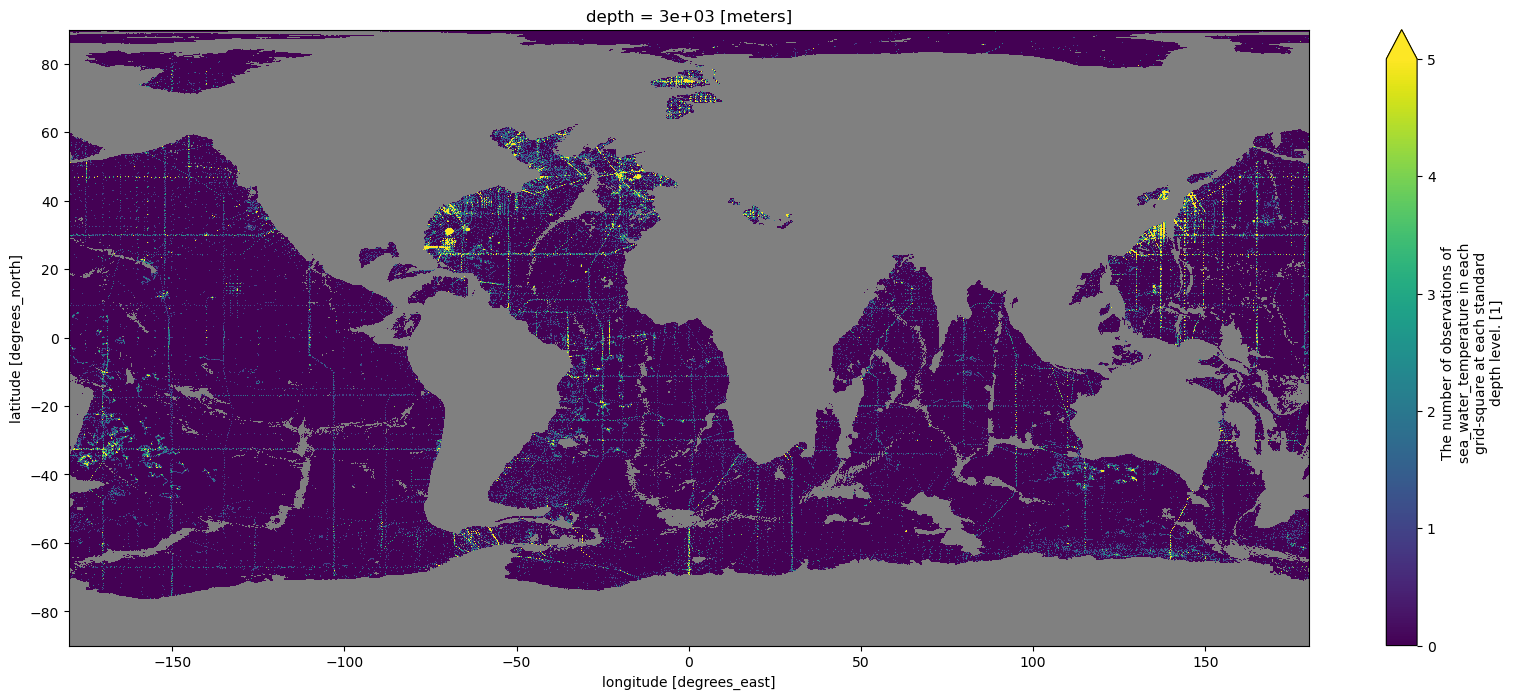

In [16]:
# Example: number of T obs underlying WAO23 at 3000m depth.
# Using seasonal decav data, which extends full depth.
# NB: use mean instead of sum so that land is nan, and then multiply by 4 to get sum.
woa23_obs = 4.0 * xr.open_mfdataset('/g/data/av17/access-nri/OM3/woa23/woa23_decav_t1[3-6]_04.nc',
                 decode_times=False).mean('time').sel(depth=3000, method='nearest').t_dd.load()

plt.figure(figsize=(20, 8))
woa23_obs.plot(vmax=5)
plt.gca().set_facecolor('gray')  # gray land points

{'SR3': [-219.875, -219.875, -67, -42],
 'P16': [-149.875, -149.875, -76, 61],
 'A16': [-24.875, -24.875, -75.01, 65],
 'I08-09': [-264.875, -264.875, -65, 15.1],
 'P02': [-237, -117, 30.02344512939453, 30.02344512939453],
 'P04': [-235, -85, 9.456768035888672, 9.456768035888672],
 'P06': [-207, -72, -32.58631896972656, -32.58631896972656],
 'OSNAP': [-62, -5, 59.007381439208984, 59.007381439208984],
 'A02': [-52, -5, 47.92713928222656, 47.92713928222656],
 'A05': [-96, -17, 24.47026252746582, 24.47026252746582],
 'A10': [-50, 17, -30.02344512939453, -30.02344512939453],
 'Mediterranean outflow': [-75, -6, 36.094486236572266, 36.094486236572266],
 'I05 west': [29, 80, -33.006614685058594, -33.006614685058594],
 'I05 east': [-280, -246, -33.006614685058594, -33.006614685058594]}

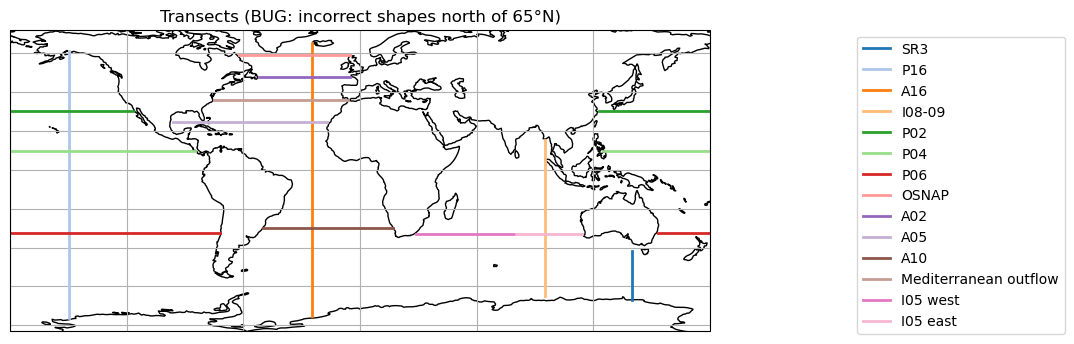

In [17]:
# Transects: [minlon, maxlon, minlat, maxlat]
# Add as many as you like, but they must be zonal or meridional
transects = {
    'SR3': [140-360, 140-360, -67, -42], # to match Kiss et al 2020
    'P16': [-150, -150, -76, 61], # to match Kiss et al 2020
    'A16': [-25, -25, -75.01, 65], # to match Kiss et al 2020
    'I08-09': [95-360, 95-360, -65, 15.1], # to match Kiss et al 2020
    'P02': [ -237, -117, 30, 30],
    'P04': [ -235, -85, 9.5, 9.5],
    'P06': [ -207, -72, -32.5, -32.5],
    'OSNAP': [-62, -5, 59, 59], # only roughly near OSNAP
    'A02': [-52, -5, 48, 48], # only roughly near A02
    'A05': [-96, -17, 24.5, 24.5],
    'A10': [-50, 17, -30, -30],
    'Mediterranean outflow': [-75, -6, 36, 36],
    'I05 west': [29, 80, -33, -33],
    'I05 east': [-280, -246, -33, -33],
}

for transect, (minlon, maxlon, minlat, maxlat) in transects.items():
    if (minlon != maxlon) and (minlat != maxlat):
        raise ValueError(f'Error in {model} {transect}: Must have either minlon == maxlon or minlat == maxlat')

transects = {k: dict(zip(["minx", "maxx", "miny", "maxy"], v)) for k, v in transects.items()}  # convert to dicts

for r, d in transects.items():
    for k, x in d.items():
        if k in ["minx", "maxx"] and x != max(-280, min(x, 80)):
            raise ValueError(f"{r} {k} = {x} is outside the range -280 to 80")
        if k in ["miny", "maxy"] and x > 65:
            print(f"{r} {k} changed from {x} to 65 to omit tripolar region")
            d[k] = 65
 
# Quantise OM3 transect locations to relevant grid
for transect, d in transects.items():
    if d['minx'] == d['maxx']:
        d['minx'] = d['maxx'] = om3data[om3exptname].sel(xh=d['minx'], method='nearest').xh.values.tolist()
    elif d['miny'] == d['maxy']:
        d['miny'] = d['maxy'] = om3data[om3exptname].sel(yh=d['miny'], method='nearest').yh.values.tolist()


# revert to array for coords
transects = {k: list(d.values()) for k, d in transects.items()}

fig = plt.figure(figsize=(10, 4))

colors = mpl.color_sequences['tab20']

ax = plt.axes(position=[0.05,0.05,0.7,0.9], projection=ccrs.PlateCarree())
ax.coastlines(resolution="110m")
ax.gridlines(draw_labels=False)

legend_elements = []
for i, (transect, (minlon, maxlon, minlat, maxlat)) in enumerate(transects.items()):
    plt.plot([minlon, maxlon], [minlat, maxlat],
             color=colors[i],
             linewidth=2,
             transform=ccrs.PlateCarree(),
             label=transect)

plt.legend(bbox_to_anchor=(1.2, 1.00))
plt.title("Transects (BUG: incorrect shapes north of 65°N)")

transects

## Load data from WOA

NB: we're taking a mean of the monthly means. This reduces seasonal bias relative to the annual mean WOA (I think!), but will also involve more interpolated values.

The alternative would be to use the WOA annual mean `/g/data/ik11/observations/woa23/woa23_decav_[ts]00_04.nc` but this needs to be converted to the appropriate temperature and salinity, and regridded to model grid.


In [18]:
obsdata = dict()

### WOA23 for comparison to OM3

In [19]:
# fragile! obs_file_pattern depends on model run!
# obs_file_pattern = "/g/data/ik11/inputs/access-om3/woa23/025/2025.10.24/woa23_ts_*"
obs_file_pattern = "/g/data/ik11/inputs/access-om3/woa23/025/2026.06.11/woa23_ts_*"  # for MC_25km_jra_iaf+wombatlite-test4-d28e0359

# WOA23 products by model grid shape: the obs is masked onto the model grid
# below (.where(om3mask)), so the two must have identical (yh, xh). Selecting by
# shape rather than hard-coding one resolution lets this notebook run at both
# 25km and 100km; an unrecognised grid falls back to the default set above.
woa23_products = {
    (1152, 1440): "/g/data/ik11/inputs/access-om3/woa23/025/2026.06.11/woa23_ts_*",   # 25km / 0.25deg grid
    (324, 360):   "/g/data/ik11/inputs/access-om3/woa23/1deg/2026.02.17/woa23_ts_*",  # 100km / 1deg grid (324 rows)
    (300, 360):   "/g/data/ik11/inputs/access-om3/woa23/1deg/2025.10.24/woa23_ts_*",  # 100km / 1deg grid (300 rows)
    (3672, 4320): "/g/data/ik11/inputs/access-om3/woa23/8km/2026.09.17/woa23_ts_*",   # 8km grid
    (3360, 4320): "/g/data/vk83/prerelease/configurations/inputs/access-om3/mom/initial_conditions/global.8km/2026.10.07/woa23_ts_*_mom.nc",  # 8km grid (hgrid 2026.10.07)
}
_grid_shape = (om3mask.sizes["yh"], om3mask.sizes["xh"])
obs_file_pattern = woa23_products.get(_grid_shape, obs_file_pattern)
print(f"model grid (yh, xh) = {_grid_shape} -> {obs_file_pattern}")


obsdata['woa23'] = xr.open_mfdataset(
        obs_file_pattern,
        chunks={"time": -1})\
    .cf.mean("time")\
    .rename({'lon': 'xh', 'lat': 'yh', 'depth': 'z_l'})\
    .where(om3mask)  # mask out interpolated values at dry points in model

model grid (yh, xh) = (1152, 1440) -> /g/data/ik11/inputs/access-om3/woa23/025/2026.06.11/woa23_ts_*


### WOA13 for comparison to OM2

In [20]:
# fragile! obs_file_pattern depends on model run!
obs_file_pattern = "/g/data/ik11/observations/woa13/025_KDS50/woa13_ts_??_mom025.nc"  # for 025deg_jra55_iaf_omip2_cycle1

obsdata['woa13'] = xr.open_mfdataset(
        obs_file_pattern,
        chunks={"time": -1},
        decode_times=xr.coders.CFDatetimeCoder(use_cftime=True))\
    .cf.mean("time")\
    .rename({'GRID_X_T': 'xt_ocean', 'GRID_Y_T': 'yt_ocean', 'ZT': 'st_ocean'})

# fix to handle slightly different st_ocean precision
obsdata['woa13'].coords['st_ocean'] = om2mask.coords['st_ocean'].values
       
obsdata['woa13'] = obsdata['woa13'].where(om2mask)  # mask out interpolated values at dry points in model

## Plot transects

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 593.30 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 289.64 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 118.69 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 593.30 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 289.64 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 118.69 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


... (89 outputs left out)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 593.30 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 289.64 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 118.69 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-0934636/notebooks/mkfigs_output_MC_25km_jra_ryf+wombatlite-test3-f4d79e82/mkmd/Transects_14.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-0934636/notebooks/mkfigs_output_MC_25km_jra_ryf+wombatlite-test3-f4d79e82/mkmd/Transects.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-0934636/notebooks/mkfigs_output_MC_25km_jra_ryf+wombatlite-test3-f4d79e82/mkmd/Transects.md successfully.
CPU times: user 2min 17s, sys: 1min 4s, total: 3min 22s
Wall time: 5min 34s


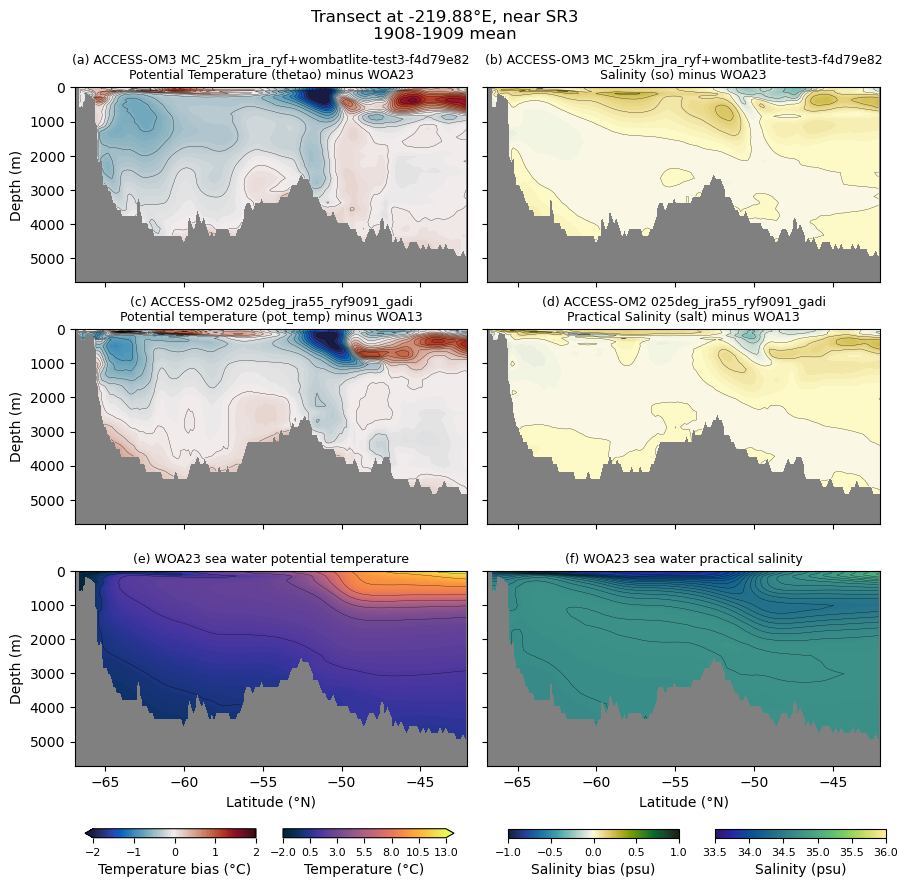

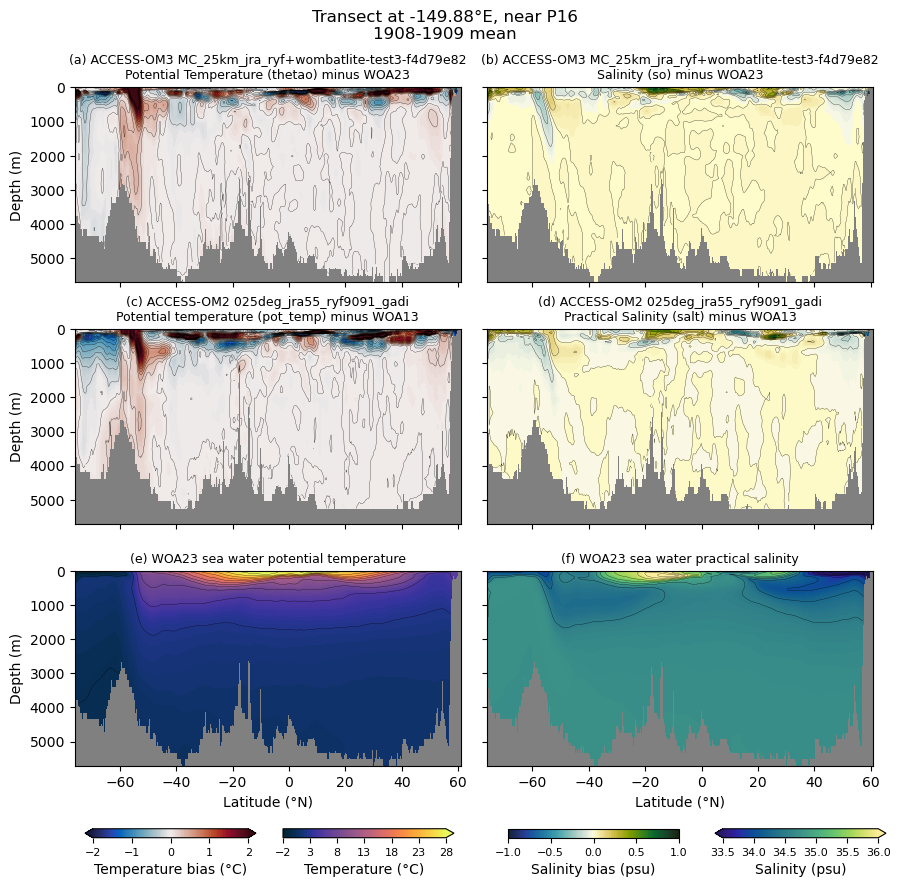

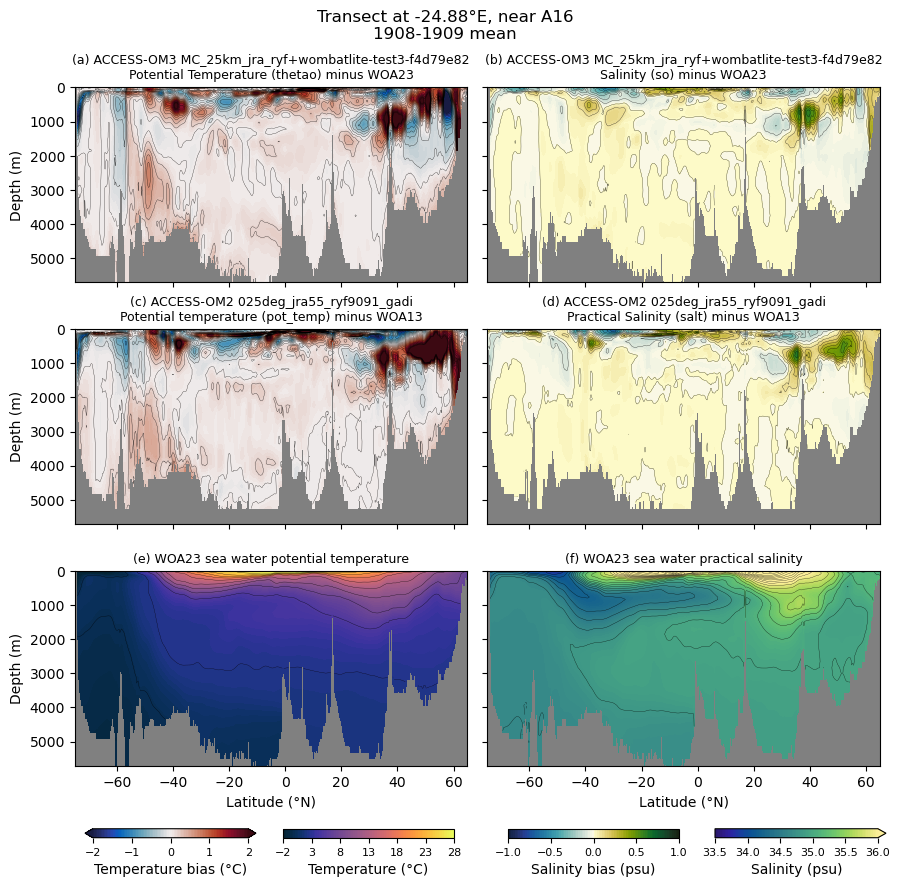

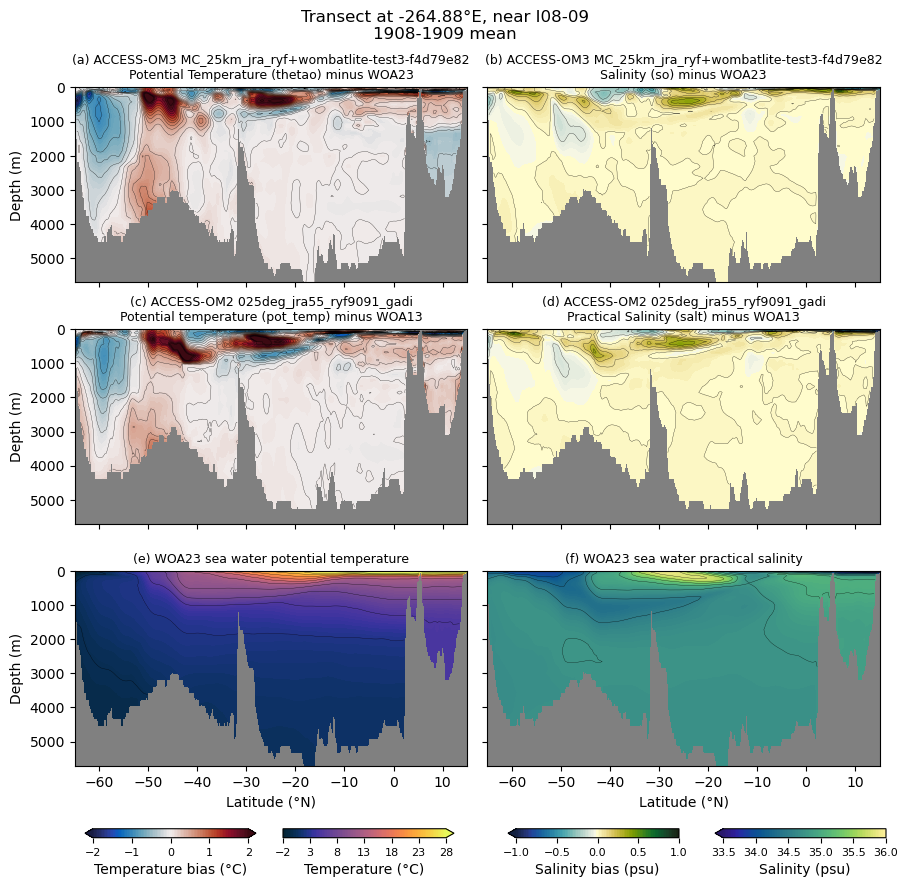

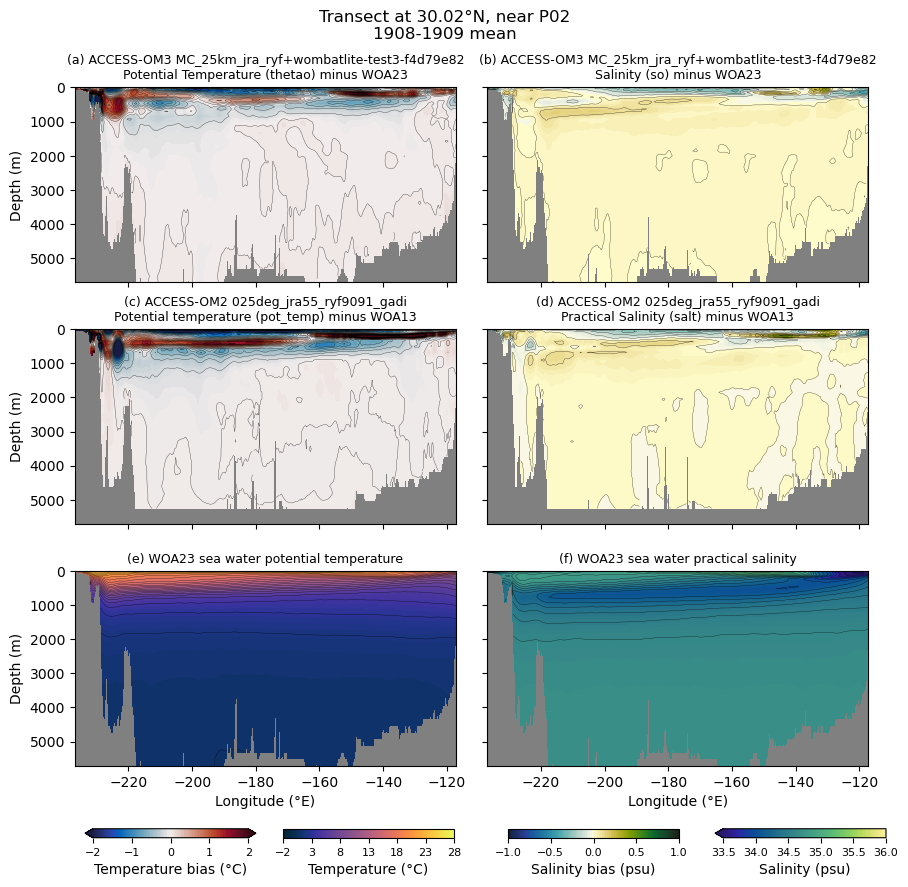

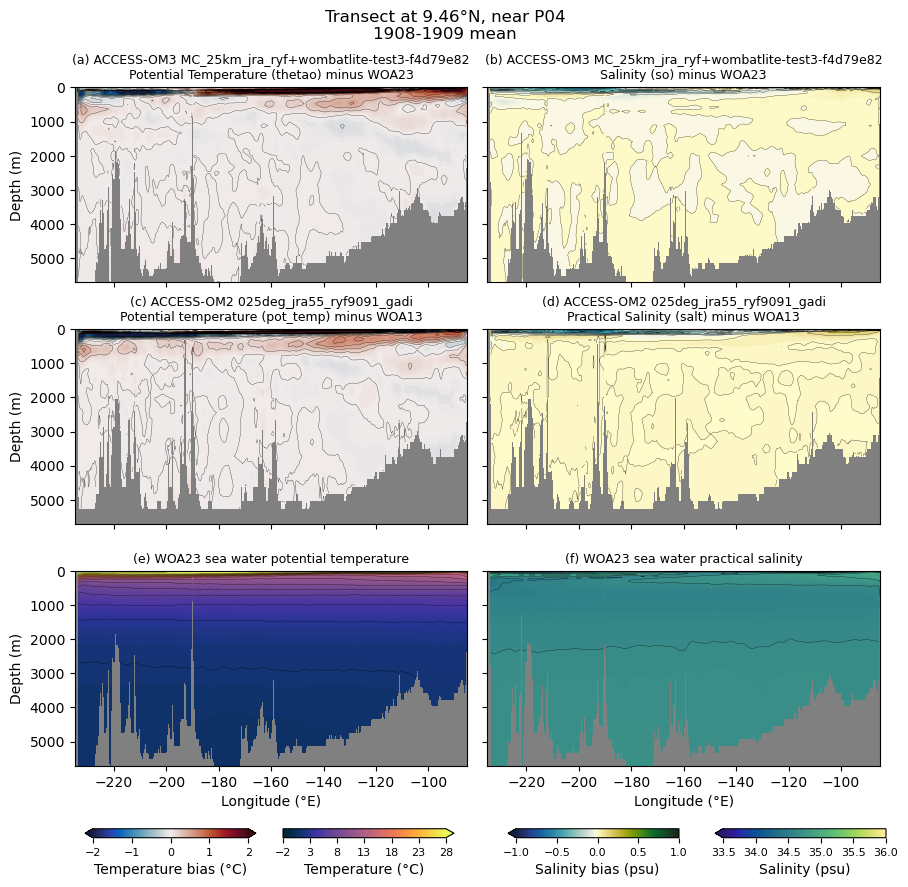

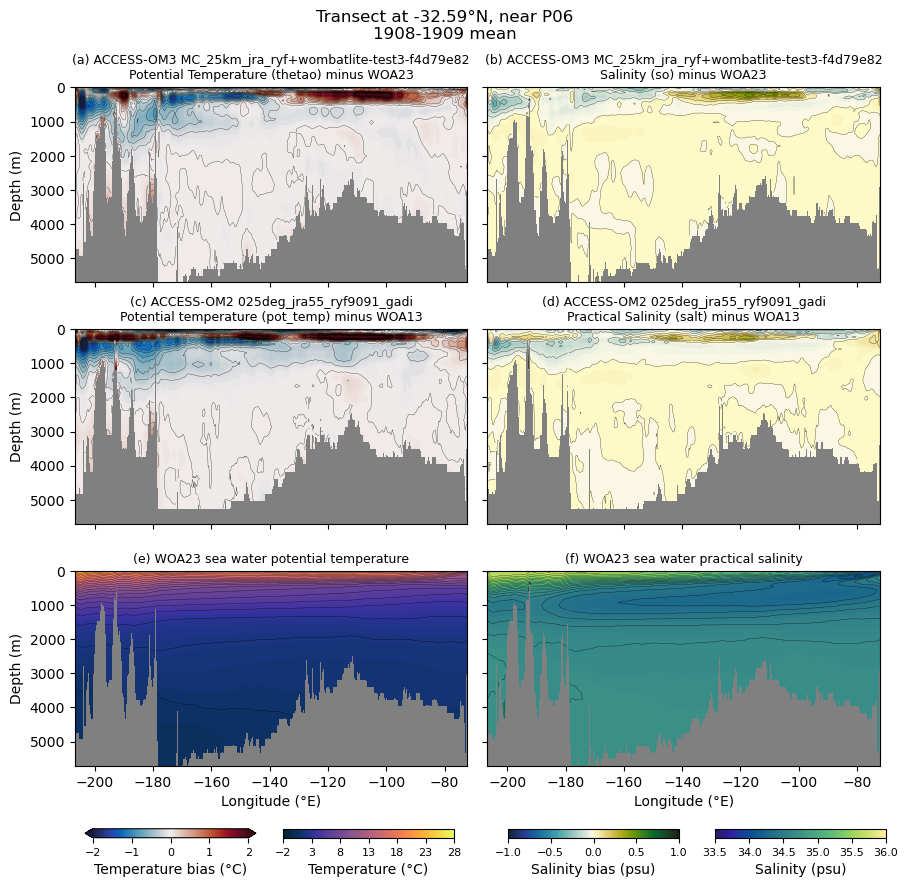

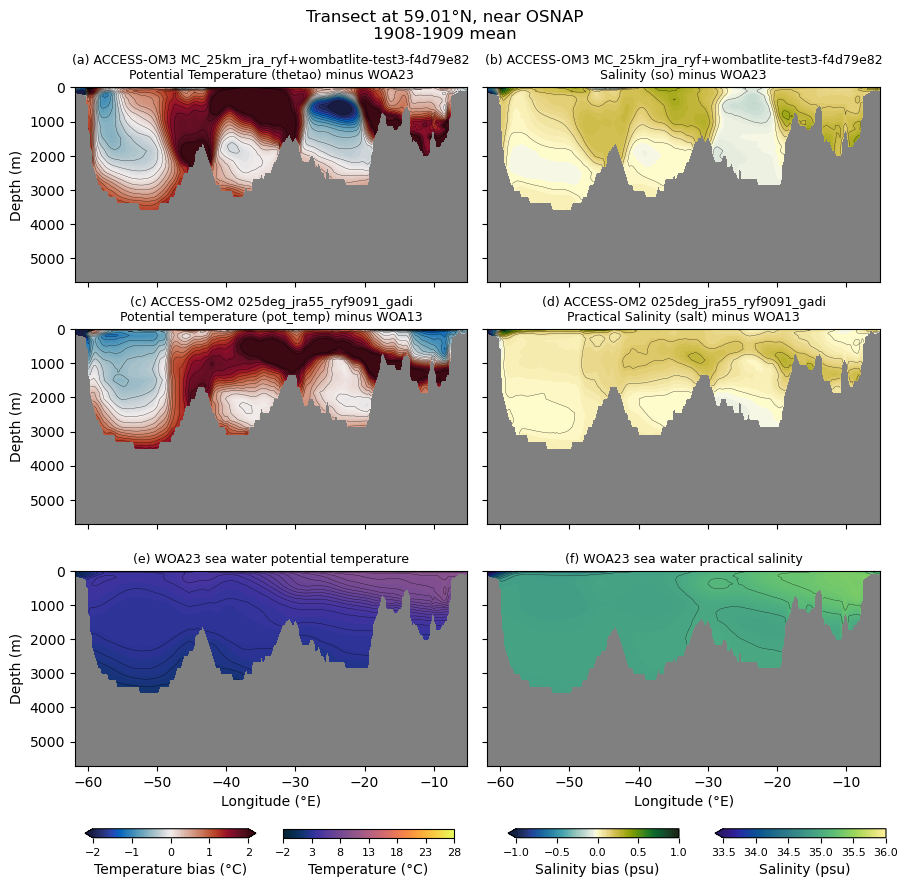

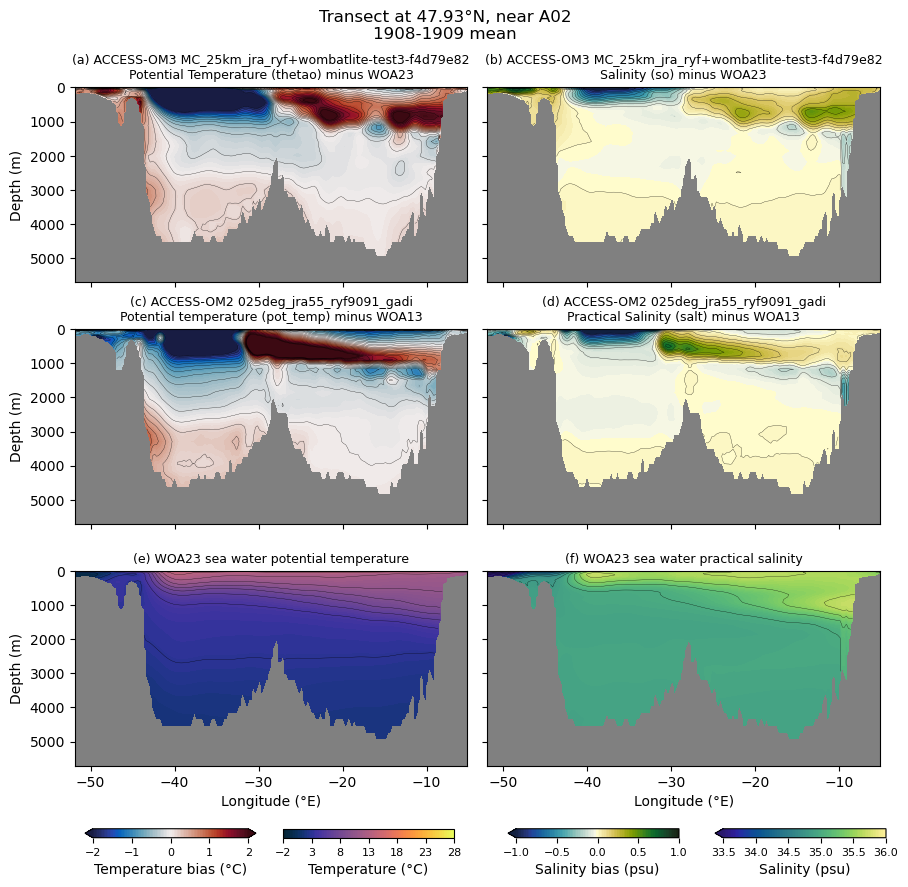

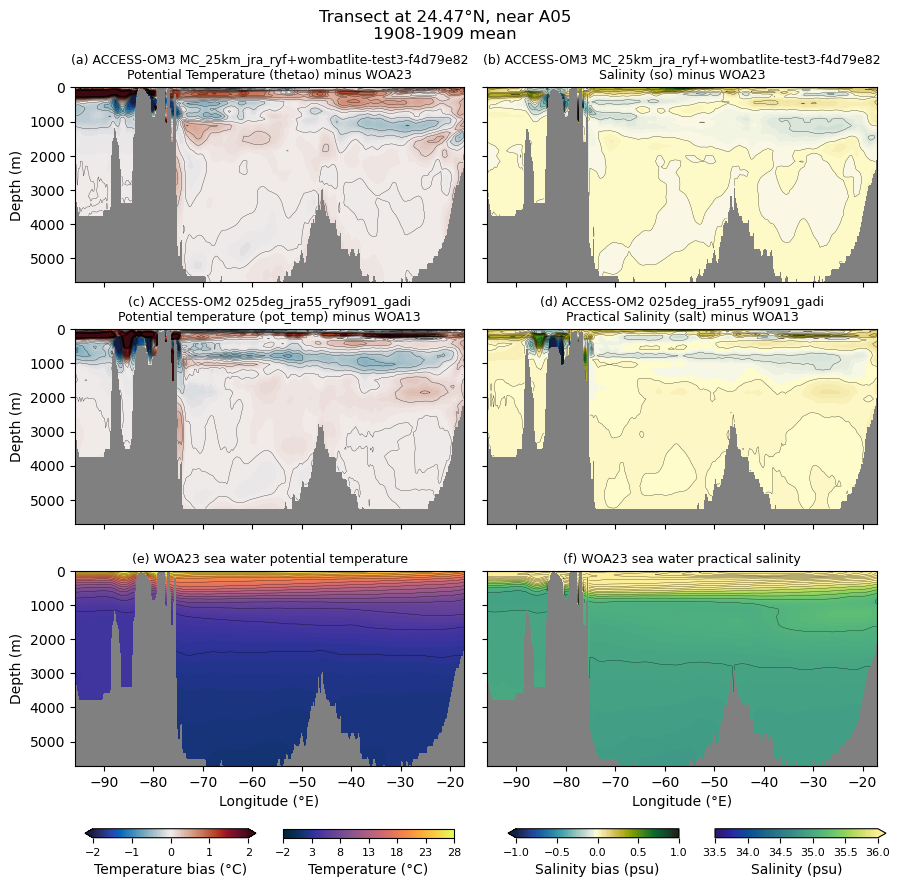

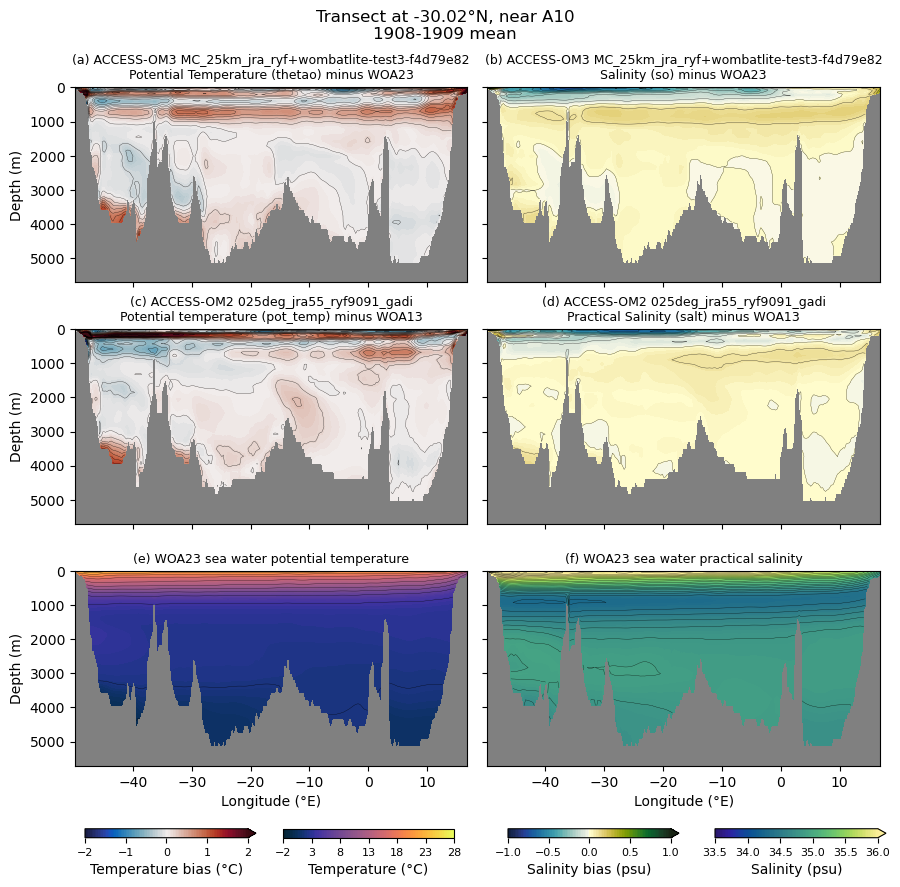

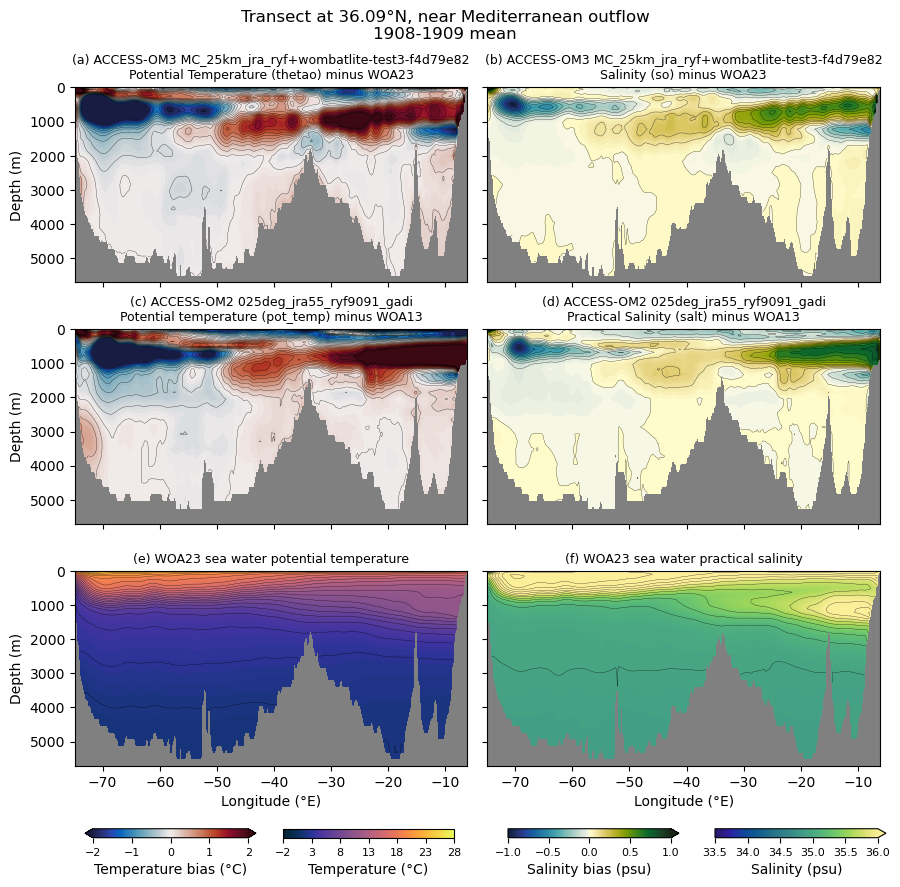

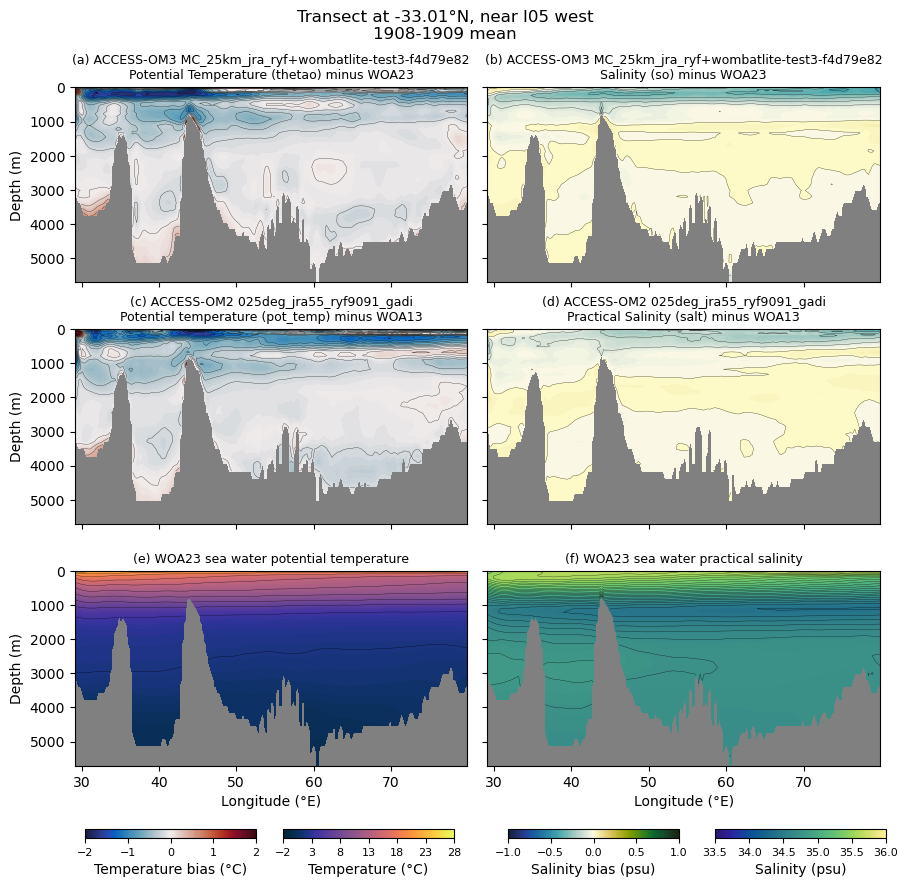

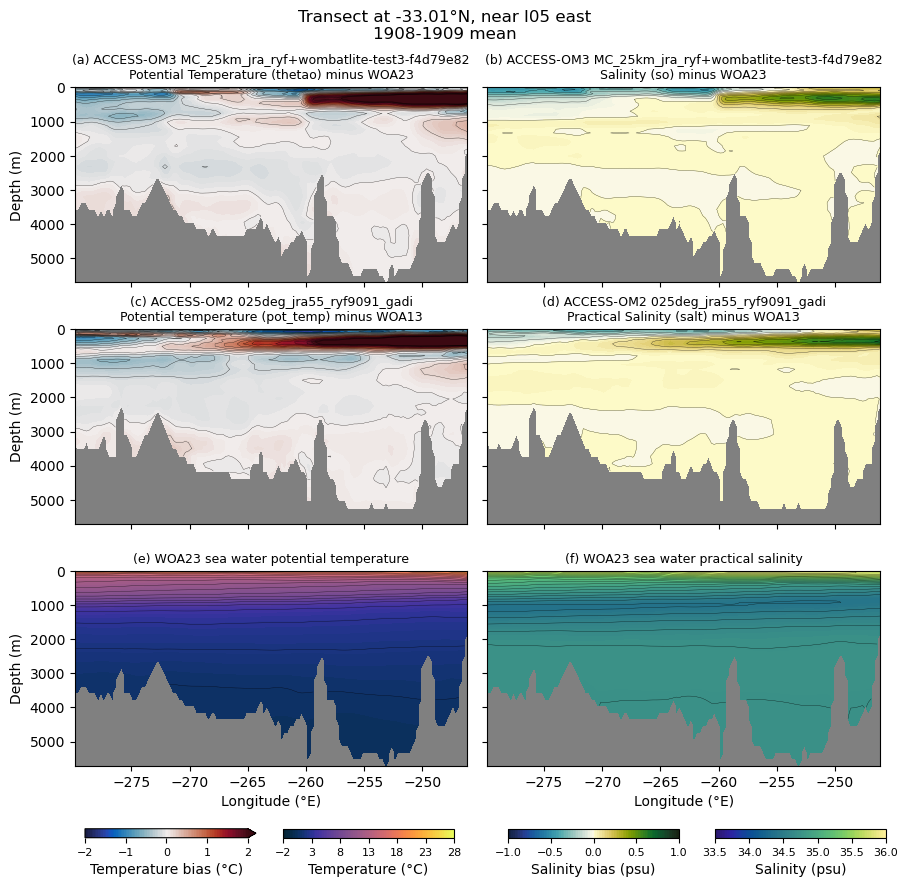

In [21]:
%%time
for transect, (minx, maxx, miny, maxy) in transects.items():
    xsel = minx if minx == maxx else slice(minx, maxx)
    ysel = miny if miny == maxy else slice(miny, maxy)
    xmethod = "nearest" if minx == maxx else None
    ymethod = "nearest" if miny == maxy else None
    woa23variable = "ptemp"  # potential temperature
    woa13variable = "temp"  # potential temperature

    om3variable = "thetao"  # potential temperature
    om2variable = "pot_temp"  # potential temperature

    npanels = 2 * (len(om3data) + len(om2data) + 1)
    nrows = (npanels+1)//2
    fig, axs = plt.subplots(nrows, 2,
                            figsize=(9, 3*nrows),
                            sharex=True, sharey=True)
    fig.suptitle(f'Transect at {f"{minx:.2f}°E" if minx == maxx else f"{miny:.2f}°N"}, near {transect}\n{period}', y=0.98)

    # Column 1: Temperature
    cmap = cmocean.cm.balance

    om3bias = {
        expt: (ds[om3variable] - obsdata['woa23'][woa23variable]).sel(xh=xsel, method=xmethod).sel(yh=ysel, method=ymethod).load()
        for expt, ds in om3data.items()
    }

    om2bias = {
        expt: (ds[om2variable] - obsdata['woa13'][woa13variable]).sel(xt_ocean=xsel, method=xmethod).sel(yt_ocean=ysel, method=ymethod).load()
        for expt, ds in om2data.items()
    }
    
    # tlim = -1
    # for da in om3bias.values():
    #     tlim = max(tlim, da.max().data)
    # for da in om2bias.values():
    #     tlim = max(tlim, da.max().data)

    tlim = 2 # to match Kiss et al 2020

    # ACCESS-OM3
    for i, (expt, da) in enumerate(om3bias.items()):
        plt.subplot(nrows, 2, 2*i+1).set_facecolor('gray')  # gray land points
        p = da.plot.contourf(
            levels=101, vmin=-tlim, vmax=tlim, cmap=cmap, add_colorbar=False,
        )
        da.plot.contour(
            levels=25, vmin=-tlim, vmax=tlim, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
        )
        plt.gca().set_ylim([0, None])
        plt.gca().invert_yaxis()
        plt.title(f"({chr(ord('a')+2*i)}) ACCESS-OM3 {expt}\n{om3data[expt][om3variable].attrs['long_name']} ({om3variable}) minus WOA23", fontsize=9)
        plt.xlabel('')
        plt.ylabel('Depth (m)')

    # ACCESS-OM2
    for i, (expt, da) in enumerate(om2bias.items(), start=i+1):
        plt.subplot(nrows, 2, 2*i+1).set_facecolor('gray')  # gray land points
        p1 = da.plot.contourf(
            levels=101, vmin=-tlim, vmax=tlim, cmap=cmap, add_colorbar=False,
        )
        da.plot.contour(
            levels=25, vmin=-tlim, vmax=tlim, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
        )
        plt.gca().set_ylim([0, None])
        plt.gca().invert_yaxis()
        plt.title(f"({chr(ord('a')+2*i)}) ACCESS-OM2 {expt}\n{om2data[expt][om2variable].attrs['long_name']} ({om2variable}) minus WOA13", fontsize=9)
        plt.xlabel('')
        plt.ylabel('Depth (m)')

    # WOA23
    i += 1
    cmap = cmocean.cm.thermal
    da = obsdata['woa23'][woa23variable].sel(xh=xsel, method=xmethod).sel(yh=ysel, method=ymethod)
    plt.subplot(nrows, 2, 2*i+1).set_facecolor('gray')  # gray land points
    p4 = da.plot.contourf(
        levels=101, cmap=cmap, add_colorbar=False,
        vmin=-2, vmax=13 if transect=='SR3' else 28  # to match Kiss et al 2020
    )
    da.plot.contour(
        levels=25, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
    )
    plt.gca().set_ylim([0, None])
    plt.gca().invert_yaxis()
    plt.title(f"({chr(ord('a')+2*i)}) WOA23 {da.attrs['standard_name'].replace('_', ' ')}", fontsize=9)
    plt.xlabel('Latitude (°N)' if minx == maxx else 'Longitude (°E)')
    plt.ylabel('Depth (m)')


    # Column 2: Salt
    om3variable = "so"
    om2variable = "salt"
    woa23variable = "salt"
    woa13variable = "salt"
    cmap = cmocean.cm.delta

    om3bias = {
        expt: (ds[om3variable] - obsdata['woa23'][woa23variable]).sel(xh=xsel, method=xmethod).sel(yh=ysel, method=ymethod).load()
        for expt, ds in om3data.items()
    }

    om2bias = {
        expt: (ds[om2variable] - obsdata['woa13'][woa13variable]).sel(xt_ocean=xsel, method=xmethod).sel(yt_ocean=ysel, method=ymethod).load()
        for expt, ds in om2data.items()
    }

    # slim = -1
    # for da in om3bias.values():
    #     slim = max(slim, da.max().data)
    # for da in om2bias.values():
    #     slim = max(slim, da.max().data)

    slim = 1.0 # to match Kiss et al 2020

    # ACCESS-OM3
    for i, (expt, da) in enumerate(om3bias.items()):
        plt.subplot(nrows, 2, 2*i+2).set_facecolor('gray')  # gray land points
        da.plot.contourf(
            levels=101, vmin=-slim, vmax=slim, cmap=cmap, add_colorbar=False,
        )
        da.plot.contour(
            levels=25, vmin=-slim, vmax=slim, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
        )
        plt.gca().set_ylim([0, None])
        plt.gca().invert_yaxis()
        plt.title(f"({chr(ord('a')+2*i+1)}) ACCESS-OM3 {expt}\n{om3data[expt][om3variable].attrs['long_name']} ({om3variable}) minus WOA23", fontsize=9)
        plt.xlabel('')

    # ACCESS-OM2
    for i, (expt, da) in enumerate(om2bias.items(), start=i+1):
        plt.subplot(nrows, 2, 2*i+2).set_facecolor('gray')  # gray land points
        s1 = da.plot.contourf(
            levels=101, vmin=-slim, vmax=slim, cmap=cmap, add_colorbar=False,
        )
        da.plot.contour(
            levels=25, vmin=-slim, vmax=slim, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
        )
        plt.gca().set_ylim([0, None])
        plt.gca().invert_yaxis()
        plt.title(f"({chr(ord('a')+2*i+1)}) ACCESS-OM2 {expt}\n{om2data[expt][om2variable].attrs['long_name']} ({om2variable}) minus WOA13", fontsize=9)
        plt.xlabel('')

    # WOA23
    cmap = cmocean.cm.haline
    i += 1
    da = obsdata['woa23'][woa23variable].sel(xh=xsel, method=xmethod).sel(yh=ysel, method=ymethod)
    plt.subplot(nrows, 2, 2*i+2).set_facecolor('gray')  # gray land points
    s4 = da.plot.contourf(
        levels=101, cmap=cmap, add_colorbar=False,
        vmin=33.5, vmax=36  # to match Kiss et al 2020
    )
    da.plot.contour(
        levels=25, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
    )
    plt.gca().set_ylim([0, None])
    plt.gca().invert_yaxis()
    plt.title(f"({chr(ord('a')+2*i+1)}) WOA23 {da.attrs['standard_name'].replace('_', ' ')}", fontsize=9)
    plt.xlabel('Latitude (°N)' if minx == maxx else 'Longitude (°E)')

    for ax in fig.get_axes():
        ax.label_outer()
    plt.tight_layout()

# to match Kiss et al 2020 https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/blob/master/figures/WOCE_transects/Plot_WOCE_transects.ipynb
    plt.subplots_adjust(bottom=0.14, hspace=0.24)
    
    ax1 = plt.axes([0.1,0.06,0.19,0.01])
    cb1 = plt.colorbar(p1, cax=ax1, orientation='horizontal', extend='both',
                       ticks=np.linspace(-tlim, tlim, 5))
    cb1.ax.xaxis.minorticks_off()
    cb1.ax.tick_params(labelsize=8)
    cb1.set_label('Temperature bias (°C)')
    
    ax2 = plt.axes([0.32,0.06,0.19,0.01])
    cb2 = plt.colorbar(p4, cax=ax2, orientation='horizontal', extend='both',
                       ticks=np.linspace(-2, 13 if transect=='SR3' else 28, 7))
    cb2.ax.xaxis.minorticks_off()
    cb2.ax.tick_params(labelsize=8)
    cb2.set_label('Temperature (°C)')
    
    ax3 = plt.axes([0.57,0.06,0.19,0.01])
    cb3 = plt.colorbar(s1, cax=ax3, orientation='horizontal', extend='both',
                       ticks=np.linspace(-slim, slim, 5))
    cb3.ax.xaxis.minorticks_off()
    cb3.ax.tick_params(labelsize=8)
    cb3.set_label('Salinity bias (psu)')
    
    ax4 = plt.axes([0.8,0.06,0.19,0.01])
    cb4 = plt.colorbar(s4, cax=ax4, orientation='horizontal', extend='both',
                       ticks=np.linspace(33.5, 36, 6))
    cb4.ax.xaxis.minorticks_off()
    cb4.ax.tick_params(labelsize=8)
    cb4.set_label('Salinity (psu)')
    mkmd.savefig(fig, f"{transect} temperature and salinity transects", f"{transect} temperature and salinity bias of ACCESS-OM3 and ACCESS-OM2 relative to WOA")

In [22]:
client.close()